# PrintGPT masking and deterministic validation: a reproducible walkthrough

This notebook follows one synthetic A4 page through Track A from source pixels
to a safe print overlay. It is deliberately visual: every intermediate mask is
shown, rejected pixels are highlighted, and the validation metrics explain the
decision.

The central rule is:

```text
printable region = allowed region
                 AND safe page interior
                 AND NOT protected existing ink
                 AND NOT calibration/layout exclusions
```

The model may propose content, but only this deterministic pipeline decides
which pixels can be printed. The source page is never modified in place.


In [1]:
from __future__ import annotations

from pathlib import Path
import json
import subprocess
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pyproject.toml").is_file():
    raise RuntimeError("Run this notebook from the PrintGPT repository or notebooks directory")

ARTIFACTS = PROJECT_ROOT / "artifacts" / "masking_notebook"
ARTIFACTS.mkdir(parents=True, exist_ok=True)
SOURCE_ROOT = PROJECT_ROOT / "src"
if str(SOURCE_ROOT) not in sys.path:
    sys.path.insert(0, str(SOURCE_ROOT))

from printgpt_alignment import DEFAULT_LAYOUT, mm_to_px, px_to_mm
from printgpt_alignment.calibration_page import render_calibration_image
from printgpt_contracts import MaskingConfig, ValidationConfig
from printgpt_masking import (
    build_masks,
    compose_preview,
    diagnostic_images,
    validate_candidate,
)


def px(value_mm: float) -> int:
    return int(round(mm_to_px(value_mm, DEFAULT_LAYOUT.dpi)))


def mask_ink_count(mask: np.ndarray) -> int:
    return int(np.count_nonzero(mask))


print(f"Repository: {PROJECT_ROOT}")
print(f"Artifacts:  {ARTIFACTS}")
print(f"Python:     {sys.version.split()[0]}")
print(f"OpenCV:     {cv2.__version__}")


Repository: C:\Users\saroy\Codes\PrintGPT
Artifacts:  C:\Users\saroy\Codes\PrintGPT\artifacts\masking_notebook
Python:     3.12.14
OpenCV:     5.0.0


## 1. Confirm the canonical A4 contract

At the nominal 300 DPI, the page is exactly 2480 columns by 3508 rows. Images
are RGB `uint8`; masks are `uint8` with values exactly `0` or `255`. The origin
is the top-left and NumPy arrays use row/column order.


In [2]:
layout = DEFAULT_LAYOUT
contract = {
    "layout_id": layout.layout_id,
    "physical_size_mm": (layout.page_width_mm, layout.page_height_mm),
    "dpi": layout.dpi,
    "raster_width_height_px": layout.raster_size_px,
    "image_shape_rows_columns": layout.image_shape,
    "one_mm_in_pixels": mm_to_px(1.0, layout.dpi),
}
display(pd.Series(contract, name="value").to_frame())

assert layout.image_shape == (3508, 2480)
assert layout.raster_size_px == (2480, 3508)


,value
layout_id,PRINTGPT-A4-CAL-V1
physical_size_mm,"(210.0, 297.0)"
dpi,300.0
raster_width_height_px,"(2480, 3508)"
image_shape_rows_columns,"(3508, 2480)"
one_mm_in_pixels,11.811024


## 2. Build a deterministic source page

The calibration raster supplies the real V1 markers, quiet zones, labels, and
layout guide. We add dark and faint strokes inside the page so the detector has
realistic line art to preserve. The array is converted from grayscale to RGB
explicitly; an OpenCV camera/scan result would similarly require an explicit
BGR-to-RGB conversion at the alignment boundary.


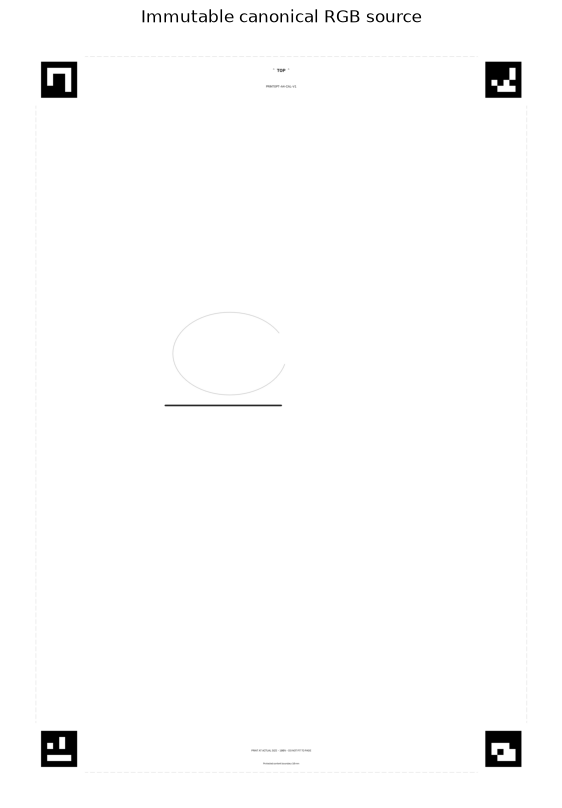

shape: (3508, 2480, 3)
dtype: uint8


In [3]:
calibration_gray = render_calibration_image(layout)
canonical_page = cv2.cvtColor(calibration_gray, cv2.COLOR_GRAY2RGB)

# Original dark stroke ending near the page centre.
cv2.line(
    canonical_page,
    (px(60), px(145)),
    (px(105), px(145)),
    (35, 35, 35),
    5,
    cv2.LINE_AA,
)

# Faint, thin arc: this should still be classified as existing content.
cv2.ellipse(
    canonical_page,
    (px(85), px(125)),
    (px(22), px(16)),
    0,
    15,
    330,
    (210, 210, 210),
    2,
    cv2.LINE_AA,
)

source_before_pipeline = canonical_page.copy()

plt.figure(figsize=(7, 10))
plt.imshow(canonical_page)
plt.title("Immutable canonical RGB source")
plt.axis("off")
plt.show()

print("shape:", canonical_page.shape)
print("dtype:", canonical_page.dtype)


## 3. Define the allowed completion region

The allowed region is required input—not an optional hint. Here it is a central
rectangle that deliberately excludes part of a later proposal. Missing allowed
region information raises an error rather than granting permission to print
across the whole sheet.


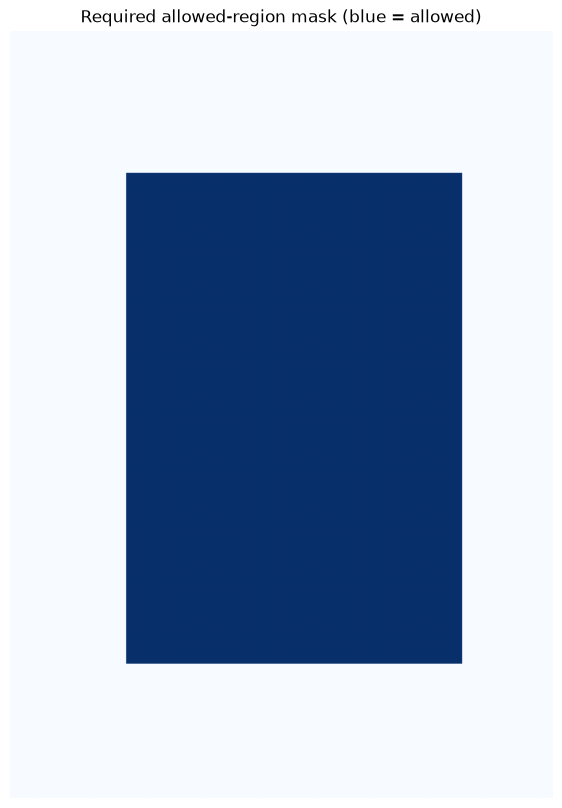

Allowed area: 3,446,784 pixels
Unique values: [0, 255]


In [4]:
allowed_region = np.zeros(layout.image_shape, dtype=np.uint8)
allowed_region[px(55):px(245), px(45):px(175)] = 255

plt.figure(figsize=(7, 10))
plt.imshow(allowed_region, cmap="Blues", vmin=0, vmax=255)
plt.title("Required allowed-region mask (blue = allowed)")
plt.axis("off")
plt.show()

print(f"Allowed area: {mask_ink_count(allowed_region):,} pixels")
print("Unique values:", np.unique(allowed_region).tolist())


## 4. Detect and protect existing content

Ink detection combines an absolute darkness threshold with local contrast, so
faint strokes can survive smooth background variation. Protection then expands
every detected pixel by a Euclidean clearance expressed in millimetres.

The default shown here is **provisional**. It is not a physical printer
calibration, and positive clearance necessarily creates a visible gap near a
stroke endpoint.


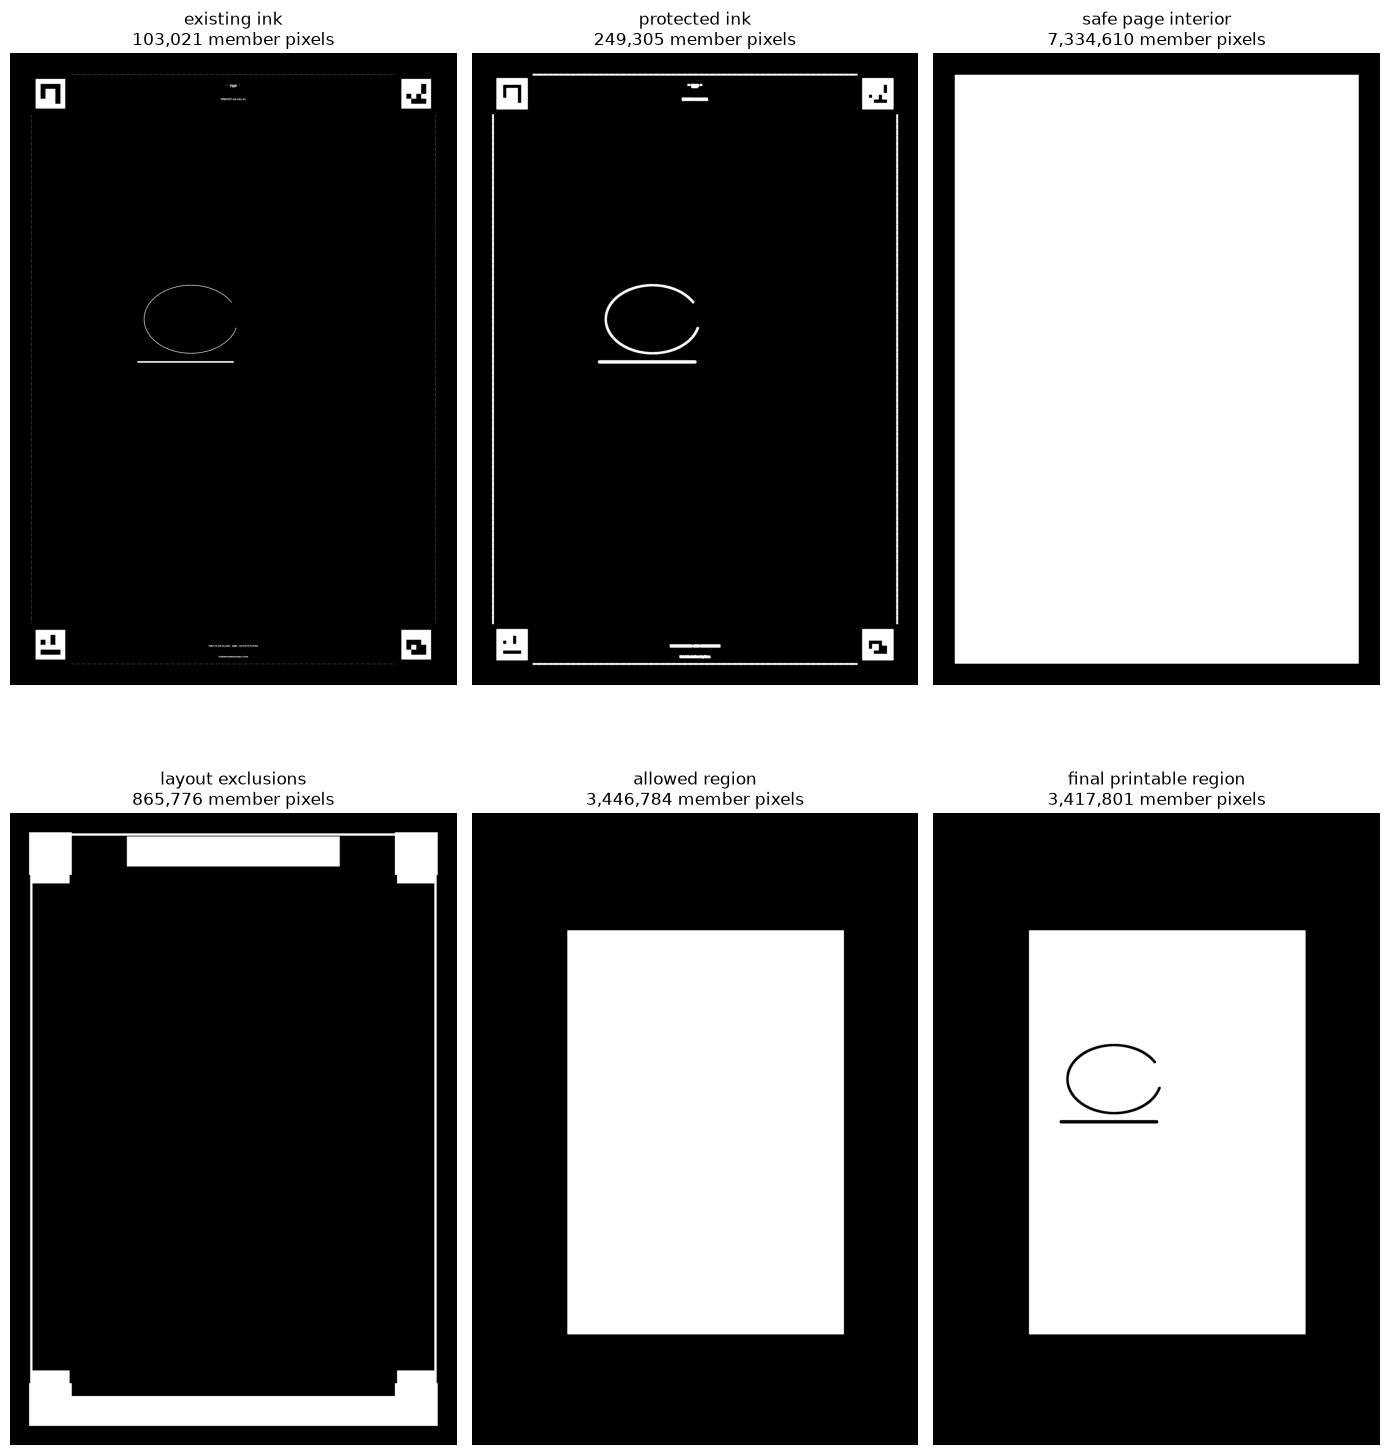

In [5]:
masking_config = MaskingConfig(
    absolute_ink_threshold=220,
    local_contrast_threshold=12,
    background_blur_mm=2.0,
    clearance_mm=0.5,
    printer_margin_mm=10.0,
    layout_guide_clearance_mm=0.5,
)

masks = build_masks(
    canonical_page,
    allowed_region,
    layout=layout,
    config=masking_config,
)

mask_rows = [
    ("existing ink", masks.existing_ink_mask),
    ("protected ink", masks.protected_mask),
    ("safe page interior", masks.safe_page_interior_mask),
    ("layout exclusions", masks.layout_exclusion_mask),
    ("allowed region", masks.allowed_region_mask),
    ("final printable region", masks.printable_region_mask),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 16))
for axis, (title, mask) in zip(axes.flat, mask_rows, strict=True):
    axis.imshow(mask, cmap="gray", vmin=0, vmax=255)
    axis.set_title(f"{title}\n{mask_ink_count(mask):,} member pixels")
    axis.axis("off")
plt.tight_layout()
plt.show()

assert all(mask.dtype == np.uint8 for _, mask in mask_rows)
assert all(mask.shape == layout.image_shape for _, mask in mask_rows)
assert all(set(np.unique(mask)).issubset({0, 255}) for _, mask in mask_rows)


## 5. Propose new ink

This synthetic candidate contains:

1. a natural continuation beginning close to the original endpoint;
2. a circle outside the allowed region; and
3. a small mark inside the printer margin.

The proposal is measured *before* clipping, so forbidden contacts remain
visible in the report.


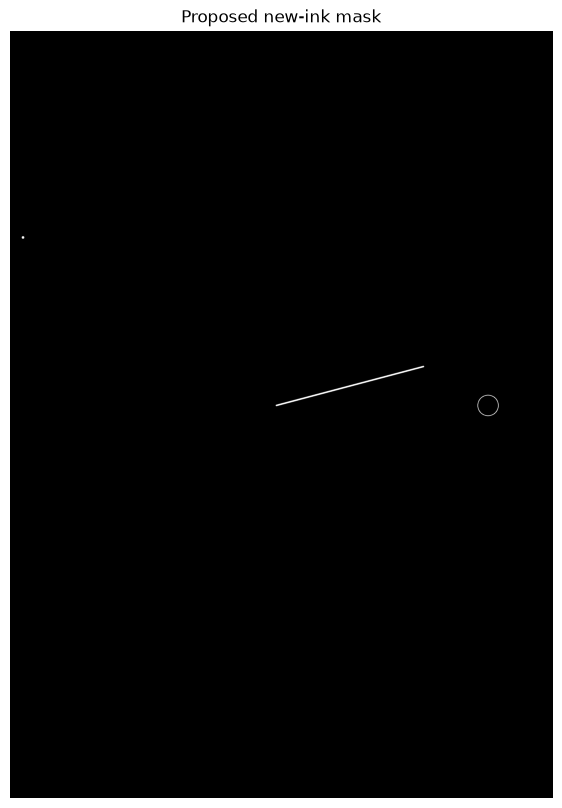

Proposed ink: 5,951 pixels


In [6]:
candidate_new_ink = np.zeros(layout.image_shape, dtype=np.uint8)
cv2.line(
    candidate_new_ink,
    (px(103), px(145)),
    (px(160), px(130)),
    255,
    5,
    cv2.LINE_8,
)
cv2.circle(candidate_new_ink, (px(185), px(145)), px(4), 255, 2, cv2.LINE_8)
cv2.circle(candidate_new_ink, (px(5), px(80)), px(0.5), 255, -1, cv2.LINE_8)

plt.figure(figsize=(7, 10))
plt.imshow(candidate_new_ink, cmap="gray", vmin=0, vmax=255)
plt.title("Proposed new-ink mask")
plt.axis("off")
plt.show()

print(f"Proposed ink: {mask_ink_count(candidate_new_ink):,} pixels")


## 6. Validate before and after clipping

The validator counts protected overlap, out-of-region pixels, margin/layout
violations, and total unique removals. It then intersects the proposal with the
printable region and validates the sanitized result for size, coverage,
clipping, and scattered noise.


In [7]:
validation_config = ValidationConfig(max_removed_fraction=0.35)
validation = validate_candidate(
    candidate_new_ink,
    masks,
    config=validation_config,
)

summary_keys = [
    "proposed_ink_count",
    "final_ink_count",
    "protected_content_overlap_pixels",
    "outside_allowed_region_pixels",
    "margin_violation_pixels",
    "layout_violation_pixels",
    "removed_pixel_count",
    "removed_fraction",
    "proposed_coverage",
    "final_coverage",
    "connected_component_count",
    "small_component_fraction",
    "final_forbidden_overlap_pixels",
]
summary = {key: validation.metrics[key] for key in summary_keys}

print("ACCEPTED" if validation.accepted else "REJECTED")
print("Reasons:", validation.reasons or ["none"])
display(pd.Series(summary, name="value").to_frame())
display(pd.Series(validation.metrics["areas_mm2"], name="area_mm²").to_frame())
display(pd.Series(validation.metrics["fraction_denominators"], name="denominator").to_frame())


ACCEPTED
Reasons: ['none']


,value
proposed_ink_count,5951.000000
final_ink_count,4746.000000
protected_content_overlap_pixels,218.000000
outside_allowed_region_pixels,987.000000
margin_violation_pixels,113.000000
layout_violation_pixels,0.000000
removed_pixel_count,1205.000000
removed_fraction,0.202487
proposed_coverage,0.000684
final_coverage,0.001389


,area_mm²
page,62364.319716
allowed_region,24708.079616
safe_page_interior,52577.744307
protected_content,1787.129042
layout_exclusions,6206.267157
printable_region,24500.316591
proposed_ink,42.659413
final_ink,34.021437
removed_ink,8.637976
protected_content_overlap,1.562721


,denominator
removed_fraction,proposed_ink_count; defined as 0.0 when propos...
proposed_coverage,page_pixel_count
final_coverage,printable_region_pixel_count; defined as 0.0 w...
small_component_fraction,final_ink_count; defined as 0.0 when final_ink...


## 7. Inspect every diagnostic image

Orange is protected source content, red is proposed ink that was removed, and
black in the final preview is the only new ink eligible for later print export.
The source scan itself is never used as a print overlay.


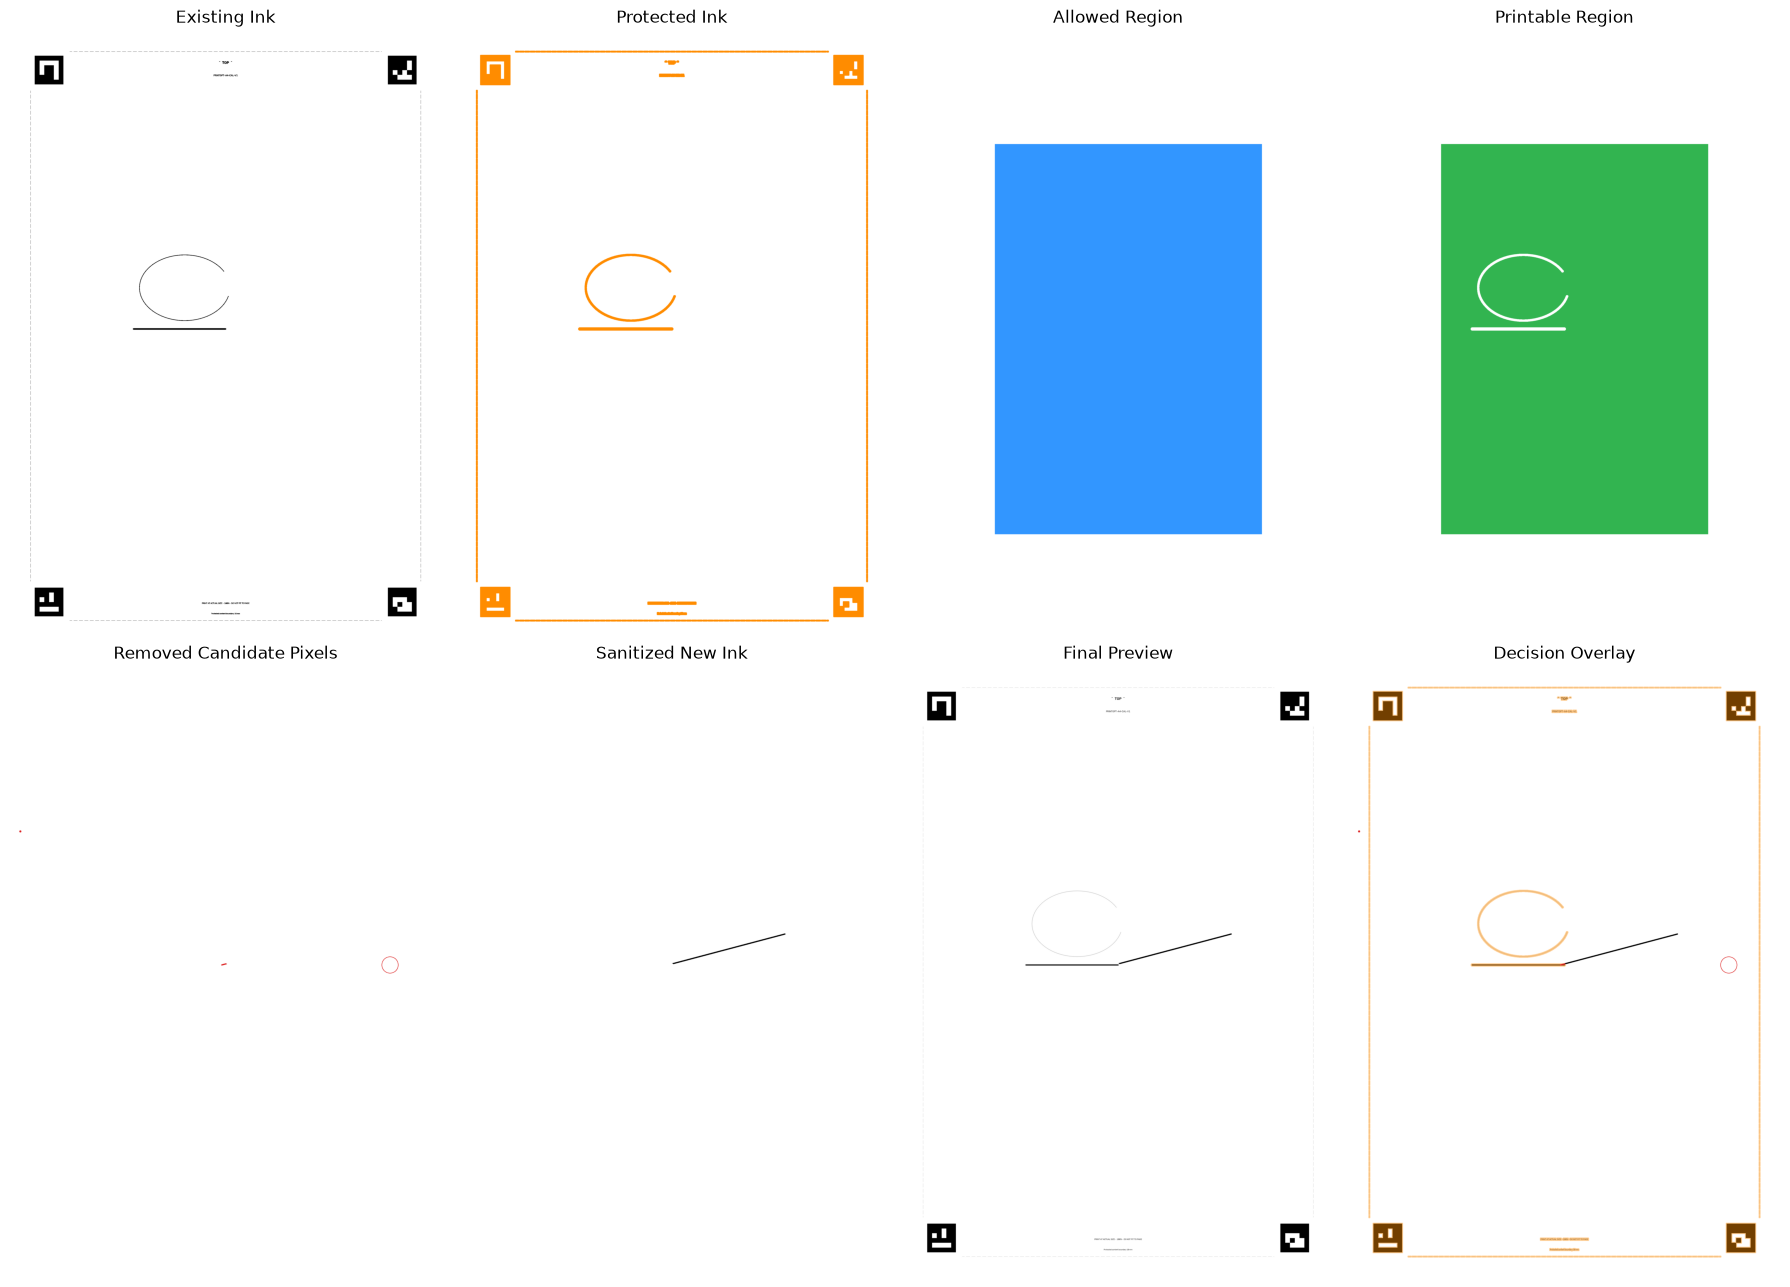

In [8]:
diagnostics = diagnostic_images(
    canonical_page,
    candidate_new_ink,
    masks,
    validation,
)

fig, axes = plt.subplots(2, 4, figsize=(18, 13))
for axis, (name, image) in zip(axes.flat, diagnostics.items(), strict=True):
    axis.imshow(image)
    axis.set_title(name.replace("_", " ").title())
    axis.axis("off")
plt.tight_layout()
plt.show()


## 8. Zoom in on the endpoint gap

Expanding existing ink creates a real digital gap. The continuation cannot
touch the original endpoint while positive clearance is active. This is a
safety/continuity tradeoff to resolve later with physical registration tests;
the validator does not hide it or copy source ink to bridge it.


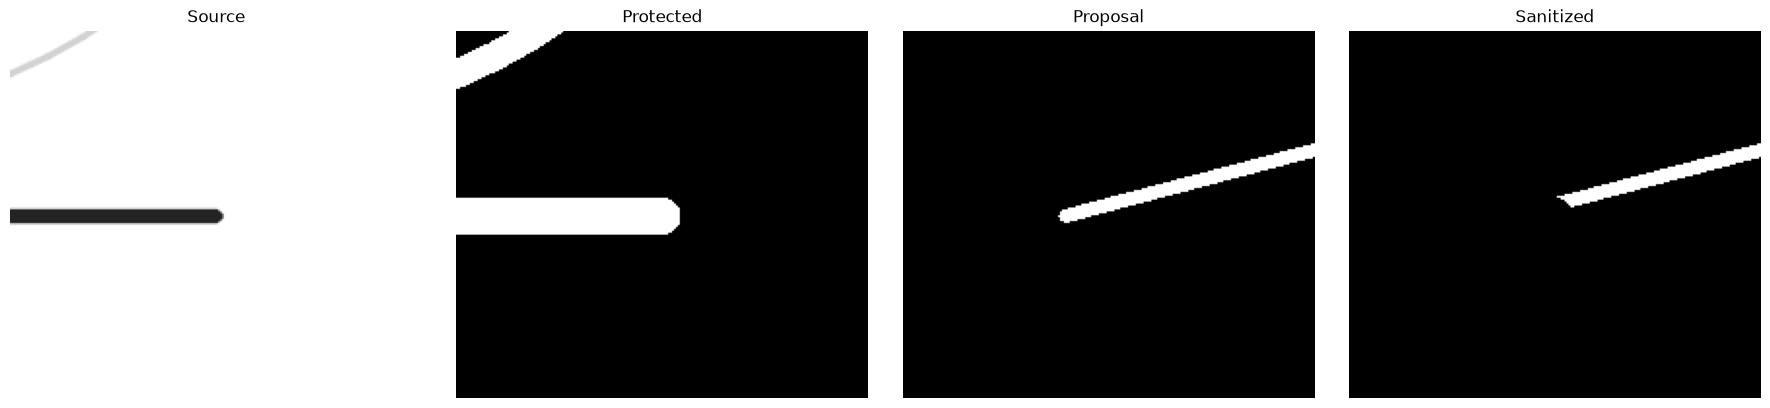

Configured clearance: 0.500 mm = 5.91 px


In [9]:
y_slice = slice(px(137), px(153))
x_slice = slice(px(96), px(114))

endpoint_views = [
    ("source", canonical_page[y_slice, x_slice]),
    ("protected", masks.protected_mask[y_slice, x_slice]),
    ("proposal", candidate_new_ink[y_slice, x_slice]),
    ("sanitized", validation.sanitized_new_ink_mask[y_slice, x_slice]),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for axis, (title, image) in zip(axes, endpoint_views, strict=True):
    axis.imshow(image, cmap=None if image.ndim == 3 else "gray", vmin=0, vmax=255)
    axis.set_title(title.title())
    axis.axis("off")
plt.tight_layout()
plt.show()

clearance_px = mm_to_px(masking_config.effective_clearance_mm, layout.dpi)
print(f"Configured clearance: {masking_config.effective_clearance_mm:.3f} mm = {clearance_px:.2f} px")


## 9. Verify the safety and immutability invariants

The sanitized result must have zero intersection with all forbidden regions.
The canonical source and proposed candidate must remain byte-for-byte unchanged.


In [10]:
forbidden = (
    (masks.allowed_region_mask == 0)
    | (masks.safe_page_interior_mask == 0)
    | (masks.protected_mask > 0)
    | (masks.layout_exclusion_mask > 0)
)
forbidden_intersection = int(
    np.count_nonzero((validation.sanitized_new_ink_mask > 0) & forbidden)
)

assert forbidden_intersection == 0
assert validation.metrics["final_forbidden_overlap_pixels"] == 0
assert np.array_equal(canonical_page, source_before_pipeline)
assert validation.sanitized_new_ink_mask is not candidate_new_ink

print("✓ zero sanitized/forbidden intersection")
print("✓ canonical RGB source preserved")
print("✓ candidate array was not modified in place")


✓ zero sanitized/forbidden intersection
✓ canonical RGB source preserved
✓ candidate array was not modified in place


## 10. Exercise deterministic rejection cases

Acceptance is not equivalent to “some pixels survived clipping.” Empty output,
excessive coverage, heavy clipping, scattered noise, and zero printable area
all produce explicit rejection reasons.


In [11]:
def decision_row(name: str, result) -> dict[str, object]:
    return {
        "case": name,
        "accepted": result.accepted,
        "final_pixels": result.metrics["final_ink_count"],
        "removed_fraction": result.metrics["removed_fraction"],
        "final_coverage": result.metrics["final_coverage"],
        "small_component_fraction": result.metrics["small_component_fraction"],
        "reasons": " | ".join(result.reasons),
    }


nearly_empty = np.zeros(layout.image_shape, dtype=np.uint8)
nearly_empty[px(100), px(120)] = 255
nearly_empty_result = validate_candidate(nearly_empty, masks)

over_coverage = masks.printable_region_mask.copy()
over_coverage_result = validate_candidate(
    over_coverage,
    masks,
    config=ValidationConfig(min_final_ink_pixels=1, max_final_coverage_fraction=0.05),
)

heavy_clip = np.zeros(layout.image_shape, dtype=np.uint8)
cv2.rectangle(heavy_clip, (px(20), px(80)), (px(42), px(150)), 255, -1)
cv2.line(heavy_clip, (px(80), px(100)), (px(95), px(100)), 255, 3)
heavy_clip_result = validate_candidate(heavy_clip, masks)

scattered = np.zeros(layout.image_shape, dtype=np.uint8)
printable_indices = np.flatnonzero(masks.printable_region_mask)
for flat_index in printable_indices[::max(1, len(printable_indices) // 120)][:120]:
    row, column = np.unravel_index(flat_index, layout.image_shape)
    scattered[row, column] = 255
scattered_result = validate_candidate(
    scattered,
    masks,
    config=ValidationConfig(
        min_final_ink_pixels=1,
        max_final_coverage_fraction=1.0,
        max_removed_fraction=1.0,
        small_component_max_pixels=1,
        max_small_component_fraction=0.30,
    ),
)

zero_allowed = np.zeros(layout.image_shape, dtype=np.uint8)
zero_allowed_masks = build_masks(
    canonical_page,
    zero_allowed,
    layout=layout,
    config=masking_config,
)
zero_allowed_result = validate_candidate(np.zeros(layout.image_shape, dtype=np.uint8), zero_allowed_masks)

rejection_table = pd.DataFrame(
    [
        decision_row("nearly empty", nearly_empty_result),
        decision_row("excessive coverage", over_coverage_result),
        decision_row("excessive clipping", heavy_clip_result),
        decision_row("scattered noise", scattered_result),
        decision_row("zero allowed area", zero_allowed_result),
    ]
)
display(rejection_table)
assert not rejection_table["accepted"].any()


,case,accepted,final_pixels,removed_fraction,final_coverage,small_component_fraction,reasons
0,nearly empty,False,1,0.000000,2.925858e-07,1.0,"sanitized addition has 1 ink pixels, below min..."
1,excessive coverage,False,3417801,0.000000,1.000000e+00,0.0,final coverage 1.000000 exceeds maximum 0.050000
2,excessive clipping,False,898,0.995862,2.627420e-04,0.0,removed fraction 0.995862 exceeds maximum 0.25...
3,scattered noise,False,120,0.000000,3.511029e-05,1.0,small-component fraction 1.000000 exceeds maxi...
4,zero allowed area,False,0,0.000000,0.000000e+00,0.0,printable region has zero area | sanitized add...


## 11. Compare positive clearance with explicit zero-clearance test mode

Zero clearance is intentionally explicit and test-only. It demonstrates the
geometric source of the endpoint gap, but it must not be mistaken for a safe
physical printer setting.


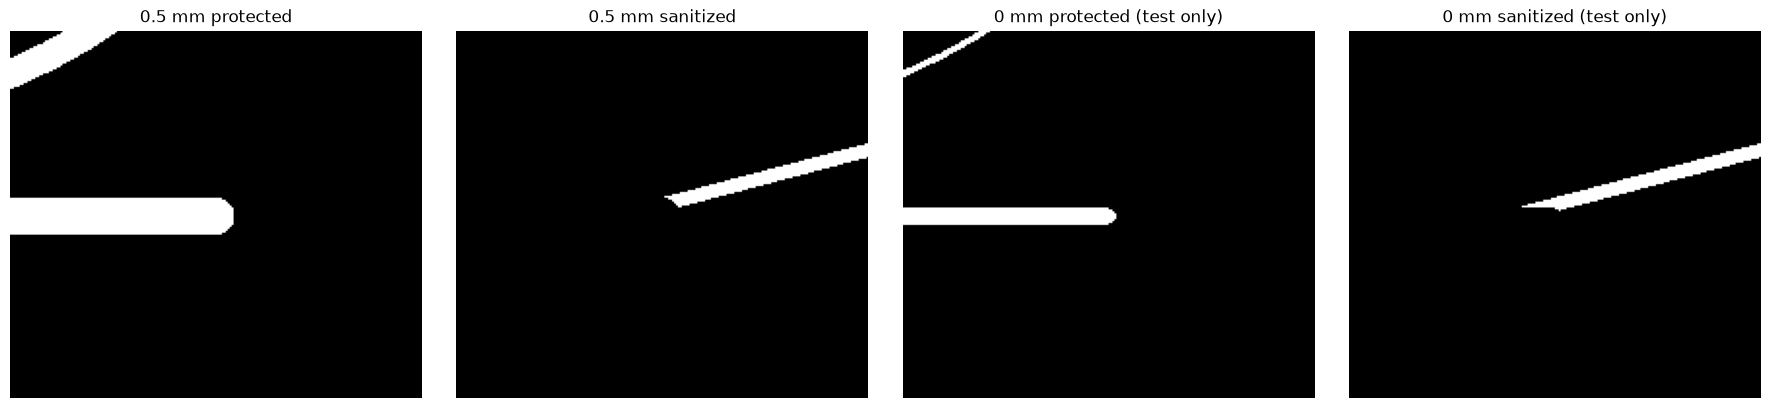

In [12]:
zero_clearance_masks = build_masks(
    canonical_page,
    allowed_region,
    layout=layout,
    config=MaskingConfig(
        clearance_mm=0.0,
        zero_clearance_test_mode=True,
        printer_margin_mm=10.0,
        layout_guide_clearance_mm=0.5,
    ),
)
zero_clearance_validation = validate_candidate(
    candidate_new_ink,
    zero_clearance_masks,
    config=validation_config,
)

comparison = [
    ("0.5 mm protected", masks.protected_mask[y_slice, x_slice]),
    ("0.5 mm sanitized", validation.sanitized_new_ink_mask[y_slice, x_slice]),
    ("0 mm protected (test only)", zero_clearance_masks.protected_mask[y_slice, x_slice]),
    ("0 mm sanitized (test only)", zero_clearance_validation.sanitized_new_ink_mask[y_slice, x_slice]),
]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for axis, (title, image) in zip(axes, comparison, strict=True):
    axis.imshow(image, cmap="gray", vmin=0, vmax=255)
    axis.set_title(title)
    axis.axis("off")
plt.tight_layout()
plt.show()


## 12. Compose the preview used by Track B

The visual critic receives the fitted, sanitized preview—not the raw proposal.
It sees protection gaps and clipping but cannot override deterministic safety.
Every revision must be validated again.


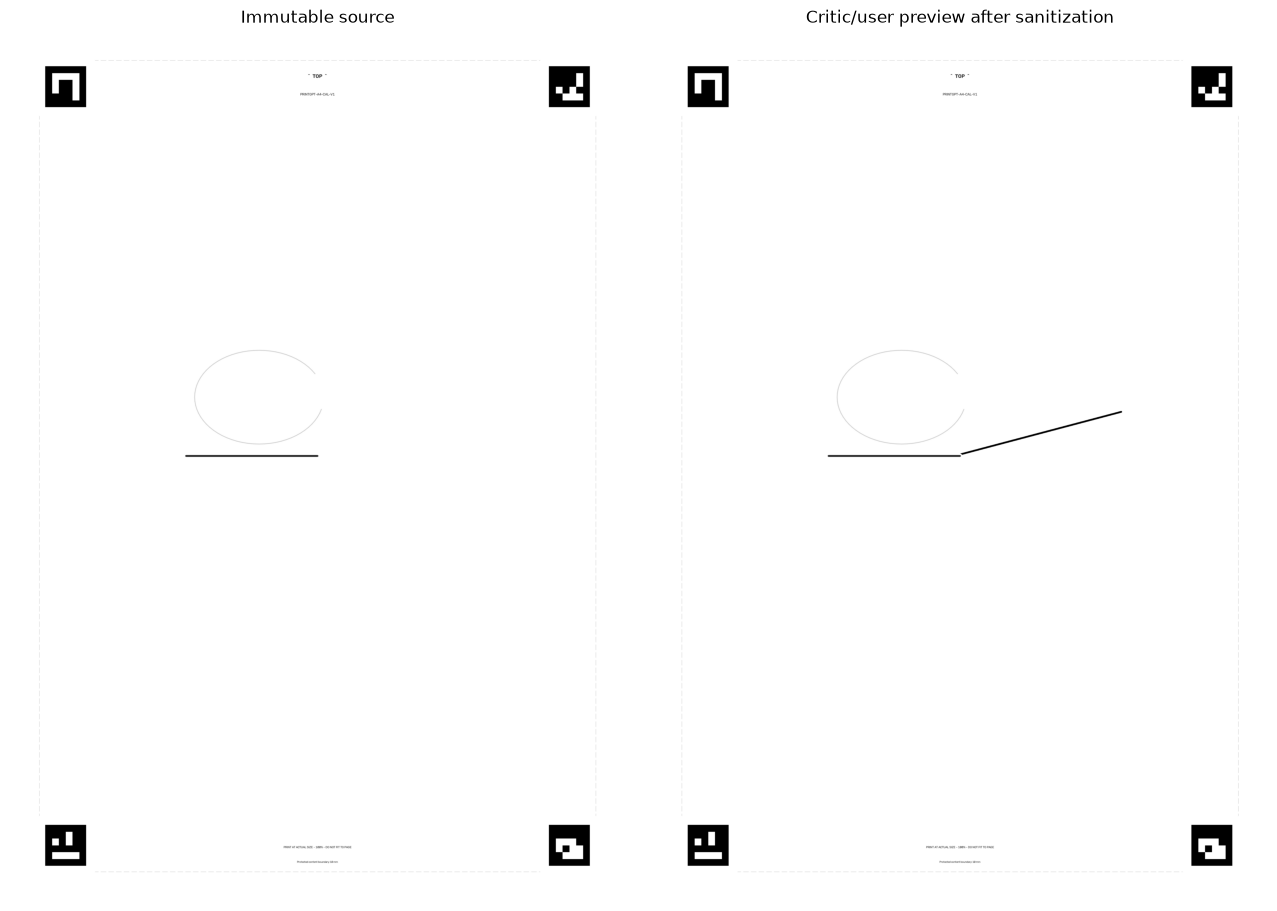

,value
accepted,True
reasons,[]
sanitized_mask_shape,"(3508, 2480)"
sanitized_ink_pixels,4746
preview_shape,"(3508, 2480, 3)"


In [13]:
preview_rgb = compose_preview(
    canonical_page,
    validation.sanitized_new_ink_mask,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 9))
axes[0].imshow(canonical_page)
axes[0].set_title("Immutable source")
axes[1].imshow(preview_rgb)
axes[1].set_title("Critic/user preview after sanitization")
for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

track_b_handoff = {
    "accepted": validation.accepted,
    "reasons": validation.reasons,
    "sanitized_mask_shape": validation.sanitized_new_ink_mask.shape,
    "sanitized_ink_pixels": validation.metrics["final_ink_count"],
    "preview_shape": preview_rgb.shape,
}
display(pd.Series(track_b_handoff, name="value").to_frame())


## 13. Save the diagnostic package

These files make a validation decision inspectable without rerunning the model.
They are written under ignored `artifacts/`, not committed to Git.


In [14]:
def write_rgb(path: Path, image: np.ndarray) -> None:
    if not cv2.imwrite(str(path), cv2.cvtColor(image, cv2.COLOR_RGB2BGR)):
        raise OSError(f"could not write {path}")


for name, image in diagnostics.items():
    write_rgb(ARTIFACTS / f"{name}.png", image)

report_path = ARTIFACTS / "validation.json"
report_path.write_text(
    json.dumps(validation.to_dict(), indent=2) + "\n",
    encoding="utf-8",
)

written = sorted(path.name for path in ARTIFACTS.iterdir())
print("Wrote:")
for name in written:
    print(" -", name)


Wrote:
 - allowed_region.png
 - decision_overlay.png
 - existing_ink.png
 - final_preview.png
 - printable_region.png
 - protected_ink.png
 - removed_candidate_pixels.png
 - sanitized_new_ink.png
 - validation.json


## 14. Run the complete automated test suite

This includes the original alignment tests plus the contracts, detection,
geometry, clipping, rejection, RGB, determinism, and endpoint-gap tests.


In [15]:
completed = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-q",
        "-p",
        "no:cacheprovider",
        f"--basetemp={ARTIFACTS / 'pytest_tmp'}",
    ],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
    check=False,
)
print(completed.stdout)
if completed.stderr:
    print(completed.stderr)
assert completed.returncode == 0, "pytest reported a failure"


...................................................................      [100%]
67 passed in 0.88s



## 15. Try your own canonical page

Set `USER_CANONICAL_RGB_PATH` to a **rectified canonical RGB file** and define an
explicit allowed rectangle. This cell is skipped by default. If the preceding
alignment step used OpenCV, remember that `cv2.imread` returns BGR and the
conversion below is required.


In [16]:
USER_CANONICAL_RGB_PATH: str | None = None
USER_ALLOWED_RECT_MM = (45.0, 55.0, 130.0, 190.0)  # x, y, width, height

if USER_CANONICAL_RGB_PATH is None:
    print("Set USER_CANONICAL_RGB_PATH to run this section.")
else:
    user_bgr = cv2.imread(USER_CANONICAL_RGB_PATH, cv2.IMREAD_COLOR)
    if user_bgr is None:
        raise FileNotFoundError(USER_CANONICAL_RGB_PATH)
    user_rgb = cv2.cvtColor(user_bgr, cv2.COLOR_BGR2RGB)
    if user_rgb.shape != (*layout.image_shape, 3):
        raise ValueError(
            f"Expected canonical shape {(*layout.image_shape, 3)}, got {user_rgb.shape}; "
            "rectify first rather than resizing here"
        )

    x_mm, y_mm, width_mm, height_mm = USER_ALLOWED_RECT_MM
    user_allowed = np.zeros(layout.image_shape, dtype=np.uint8)
    user_allowed[
        px(y_mm):px(y_mm + height_mm),
        px(x_mm):px(x_mm + width_mm),
    ] = 255
    user_masks = build_masks(
        user_rgb,
        user_allowed,
        layout=layout,
        config=masking_config,
    )
    plt.figure(figsize=(7, 10))
    plt.imshow(user_masks.printable_region_mask, cmap="gray", vmin=0, vmax=255)
    plt.title("Printable region for user page")
    plt.axis("off")
    plt.show()


Set USER_CANONICAL_RGB_PATH to run this section.


## Reading the result

- An accepted result means the sanitized raster passed the configured digital
  checks. It does **not** guarantee semantic quality or physical registration.
- `removed_fraction` is relative to proposed ink; `final_coverage` is relative
  to printable area; `small_component_fraction` is relative to final ink.
- A zero digital intersection with forbidden pixels is necessary, but actual
  printer feed error still requires measurement.
- Preserve `sanitized_new_ink_mask` as the only later print-overlay source. An
  empty mask corresponds to an all-white print raster.
